# Лабораторная работа 2. Рекомендательные системы

**Датасет:** [KuaiRec](https://github.com/chongminggao/KuaiRec) (Kuaishou, CIKM 2022). Открытый полностью наблюдаемый датасет коротких видео: у каждого пользователя зафиксировано, какие видео ему показывали и какие он посмотрел. Лицензия CC BY-SA 4.0, источник [Zenodo, запись 18164998](https://zenodo.org/records/18164998). Запрещённые источники, Kaggle и MovieLens, не используются.

**Постановка.** Выбрать датасет, провести разведочный анализ с оценкой качества данных, выделить целевую переменную, реализовать не менее трёх методов формирования рекомендации из разных семейств, вычислить на тестовой выборке не менее четырёх метрик качества, включая метрику ранжирования и специфичную для рекомендательных систем метрику, сравнить методы, дать интерпретацию и предложить улучшения.

**Исходные данные и подготовленная выборка.** В оригинальном датасете таблица `big_matrix.csv` содержит 12 530 806 записей о показах коротких видео 7 176 пользователям по 10 728 видео за период с 23 июня по 9 сентября 2020 года. Для лабораторной работы подготовлена выборка релевантных взаимодействий: 1 200 самых популярных видео и 1 500 случайно выбранных пользователей, что даёт 412 422 взаимодействия. Логика отбора описана в ячейке 4, объём выбран так, чтобы все методы обучались и считались на ноутбуке за разумное время.

## Ячейка 1. Подготовка окрунения и загрузка данных

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.sparse as sp
import seaborn as sns
from sklearn.preprocessing import normalize

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)

SEED = 42
DATA_PATH = "kuairec_interactions.csv"

try:
    interactions = pd.read_csv(DATA_PATH)
except FileNotFoundError as error:
    raise FileNotFoundError(
        f"Файл {DATA_PATH} не найден в рабочей директории ноутбука"
    ) from error

print(f"Загружено взаимодействий: {len(interactions)}")
print(f"Пользователей: {interactions['user_idx'].nunique()}")
print(f"Видео: {interactions['item_id'].nunique()}")
interactions.head()

Загружено взаимодействий: 412422
Пользователей: 1500
Видео: 1200


,user_idx,item_id,watch_ratio,timestamp,date
0,0,250,1.182899,1593903045,20200705
1,0,7,1.810714,1593904481,20200705
2,0,630,1.598990,1593904667,20200705
3,0,248,1.404445,1593905869,20200705
4,0,435,1.568888,1593906134,20200705


### Описание полей

| Поле | Тип | Смысл |
| --- | --- | --- |
| `user_idx` | int32 | идентификатор пользователя, перенумерован без пропусков |
| `item_id` | int32 | идентификатор видео, перенумерован без пропусков |
| `watch_ratio` | float32 | отношение длительности просмотра к длительности видео |
| `timestamp` | int64 | момент начала просмотра, unix-время в секундах |
| `date` | int32 | дата просмотра в формате `ГГГГММДД` |

Каждая строка означает, что пользователю было показано видео и он его посмотрел с коэффициентом `watch_ratio`. Значение больше единицы означает пересмотр: пользователь досмотрел видео до конца и запустил его снова.

In [2]:
print(interactions.dtypes)
print()
print(interactions.describe().T)
print()
print("Пропуски по столбцам:")
print(interactions.isna().sum().to_string())
print()
print("Полные дубликаты строк:", int(interactions.duplicated().sum()))
print("Дубликаты пар (пользователь, видео):", int(interactions.duplicated(["user_idx", "item_id"]).sum()))

user_idx         int64
item_id          int64
watch_ratio    float64
timestamp        int64
date             int64
dtype: object

                count          mean           std           min           25%           50%           75%           max
user_idx     412422.0  7.642731e+02  4.307732e+02  0.000000e+00  3.930000e+02  7.730000e+02  1.131000e+03  1.499000e+03
item_id      412422.0  6.041431e+02  3.473912e+02  0.000000e+00  3.030000e+02  6.070000e+02  9.050000e+02  1.199000e+03
watch_ratio  412422.0  1.958044e+00  2.651776e+00  1.000000e+00  1.211378e+00  1.497018e+00  1.986968e+00  2.466937e+02
timestamp    412422.0  1.596673e+09  1.529336e+06  1.593553e+09  1.596280e+09  1.596632e+09  1.597059e+09  1.599692e+09
date         412422.0  2.020080e+07  5.165167e+01  2.020070e+07  2.020080e+07  2.020080e+07  2.020081e+07  2.020090e+07

Пропуски по столбцам:
user_idx       0
item_id        0
watch_ratio    0
timestamp      0
date           0



Полные дубликаты строк: 0
Дубликаты пар (пользователь, видео): 0


## Ячейка 2. Целевая переменная

**Что именно рекомендуем.** Модель для каждого пользователя должна ранжировать список видео, которые он посмотрит целиком и положительно оценит. Поэтому бинарная целевая метка пары пользователь и видео равна 1, если коэффициент просмотра не меньше единицы, то есть доля просмотренного составляет 100 процентов или видео было досмотрено и пересмотрено.

**Как различаются положительные и отрицательные примеры.** КuaiRec является полностью наблюдаемым датасетом: матрица пользовательitem плотная, и для каждого пользователя известно не только то, что он посмотрел, но и то, что ему показывали, а он не посмотрел. В подготовленной выборке оставлены только положительные пары с `watch_ratio >= 1`, а отрицательные примеры это не наблюдённые пары внутри той же рамки пользователей и видео. Именно их ранжирование и есть задача, поэтому в коде они не хранятся явно, а учитываются через разреженную матрицу: для видео, которое пользователь уже посмотрел, оценка принудительно зануляется, и рекомендация не может содержать его.

In [3]:
interactions["is_relevant"] = (interactions["watch_ratio"] >= 1.0).astype("int8")

n_users_full = int(interactions["user_idx"].nunique())
n_items_full = int(interactions["item_id"].nunique())
observed = len(interactions)

print("Распределение целевой метки в загруженной выборке:")
print(interactions["is_relevant"].value_counts().to_string())
print()
print(f"Положительных пар (watch_ratio >= 1): {observed}")
print(f"Всего пар в рамке {n_users_full} на {n_items_full}: {n_users_full * n_items_full}")
print(f"Доля положительных пар в рамке: {observed / (n_users_full * n_items_full):.4f}")
print(f"Отрицательных примеров (не наблюдённые пары): {n_users_full * n_items_full - observed}")
print()
print("Распределение watch_ratio по квантилям:")
print(interactions["watch_ratio"].quantile([0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).round(3).to_string())

Распределение целевой метки в загруженной выборке:
is_relevant
1    412422

Положительных пар (watch_ratio >= 1): 412422
Всего пар в рамке 1500 на 1200: 1800000
Доля положительных пар в рамке: 0.2291
Отрицательных примеров (не наблюдённые пары): 1387578

Распределение watch_ratio по квантилям:
0.05    1.041
0.25    1.211
0.50    1.497
0.75    1.987
0.95    3.857
0.99    8.836


## Ячейка 3. Отчёт по качеству данных

Проверяем пропуски, дубли и выбросы.

In [4]:
missing_total = int(interactions.isna().sum().sum())
duplicate_pairs = int(interactions.duplicated(["user_idx", "item_id"]).sum())
watch_outliers = int((interactions["watch_ratio"] > 3.0).sum())
zero_play = int((interactions["watch_ratio"] <= 0.0).sum())
wrong_types = int(interactions["watch_ratio"].isna().sum())

quality_report = pd.DataFrame(
    [
        {
            "Проверка": "Пропуски (NaN)",
            "Результат": f"{missing_total} значений",
            "Интерпретация": "Пропусков нет, импутация не требуется",
        },
        {
            "Проверка": "Дубликаты пар (пользователь, видео)",
            "Результат": f"{duplicate_pairs} строк",
            "Интерпретация": "Повторов нет, каждая пара встречается один раз",
        },
        {
            "Проверка": "Выбросы watch_ratio > 3",
            "Результат": f"{watch_outliers} строк ({watch_outliers / observed:.4f})",
            "Интерпретация": "Многократные пересмотры коротких видео, поведение легитимно, строки сохраняются",
        },
        {
            "Проверка": "watch_ratio <= 0 (нулевой просмотр)",
            "Результат": f"{zero_play} строк",
            "Интерпретация": "Нулевых просмотров нет",
        },
        {
            "Проверка": "Пропуски после приведения типов",
            "Результат": f"{wrong_types} значений",
            "Интерпретация": "Все столбцы приведены к числовым типам без потерь",
        },
    ]
)

quality_report

,Проверка,Результат,Интерпретация
0,Пропуски (NaN),0 значений,"Пропусков нет, импутация не требуется"
1,"Дубликаты пар (пользователь, видео)",0 строк,"Повторов нет, каждая пара встречается один раз"
2,Выбросы watch_ratio > 3,36876 строк (0.0894),"Многократные пересмотры коротких видео, поведе..."
3,watch_ratio <= 0 (нулевой просмотр),0 строк,Нулевых просмотров нет
4,Пропуски после приведения типов,0 значений,Все столбцы приведены к числовым типам без потерь


### Полнота матрицы и хвост распределений

Плотность матрицы влияет на выбор методов и на интерпретацию метрик, поэтому считаем её отдельно.

In [5]:
density = observed / (n_users_full * n_items_full)

per_user = interactions.groupby("user_idx").size().sort_values()
per_item = interactions.groupby("item_id").size().sort_values()

print(f"Пользователей: {n_users_full}")
print(f"Видео: {n_items_full}")
print(f"Взаимодействий: {observed}")
print(f"Плотность матрицы: {density:.4f}")
print()
print("Активность пользователей (число взаимодействий):")
print(per_user.describe().round(2).to_string())
print()
print("Популярность видео (число взаимодействий):")
print(per_item.describe().round(2).to_string())
print()
print(f"Пользователей с менее чем 5 взаимодействиями: {int((per_user < 5).sum())}")
print(f"Видео с менее чем 5 взаимодействиями: {int((per_item < 5).sum())}")

Пользователей: 1500
Видео: 1200
Взаимодействий: 412422
Плотность матрицы: 0.2291

Активность пользователей (число взаимодействий):
count    1500.00
mean      274.95
std       199.55
min         4.00
25%        78.75
50%       269.00
75%       430.00
max       885.00

Популярность видео (число взаимодействий):
count    1200.00
mean      343.68
std       100.15
min       195.00
25%       268.75
50%       314.50
75%       394.25
max       739.00

Пользователей с менее чем 5 взаимодействиями: 1
Видео с менее чем 5 взаимодействиями: 0


### Визуализация структуры взаимодействий

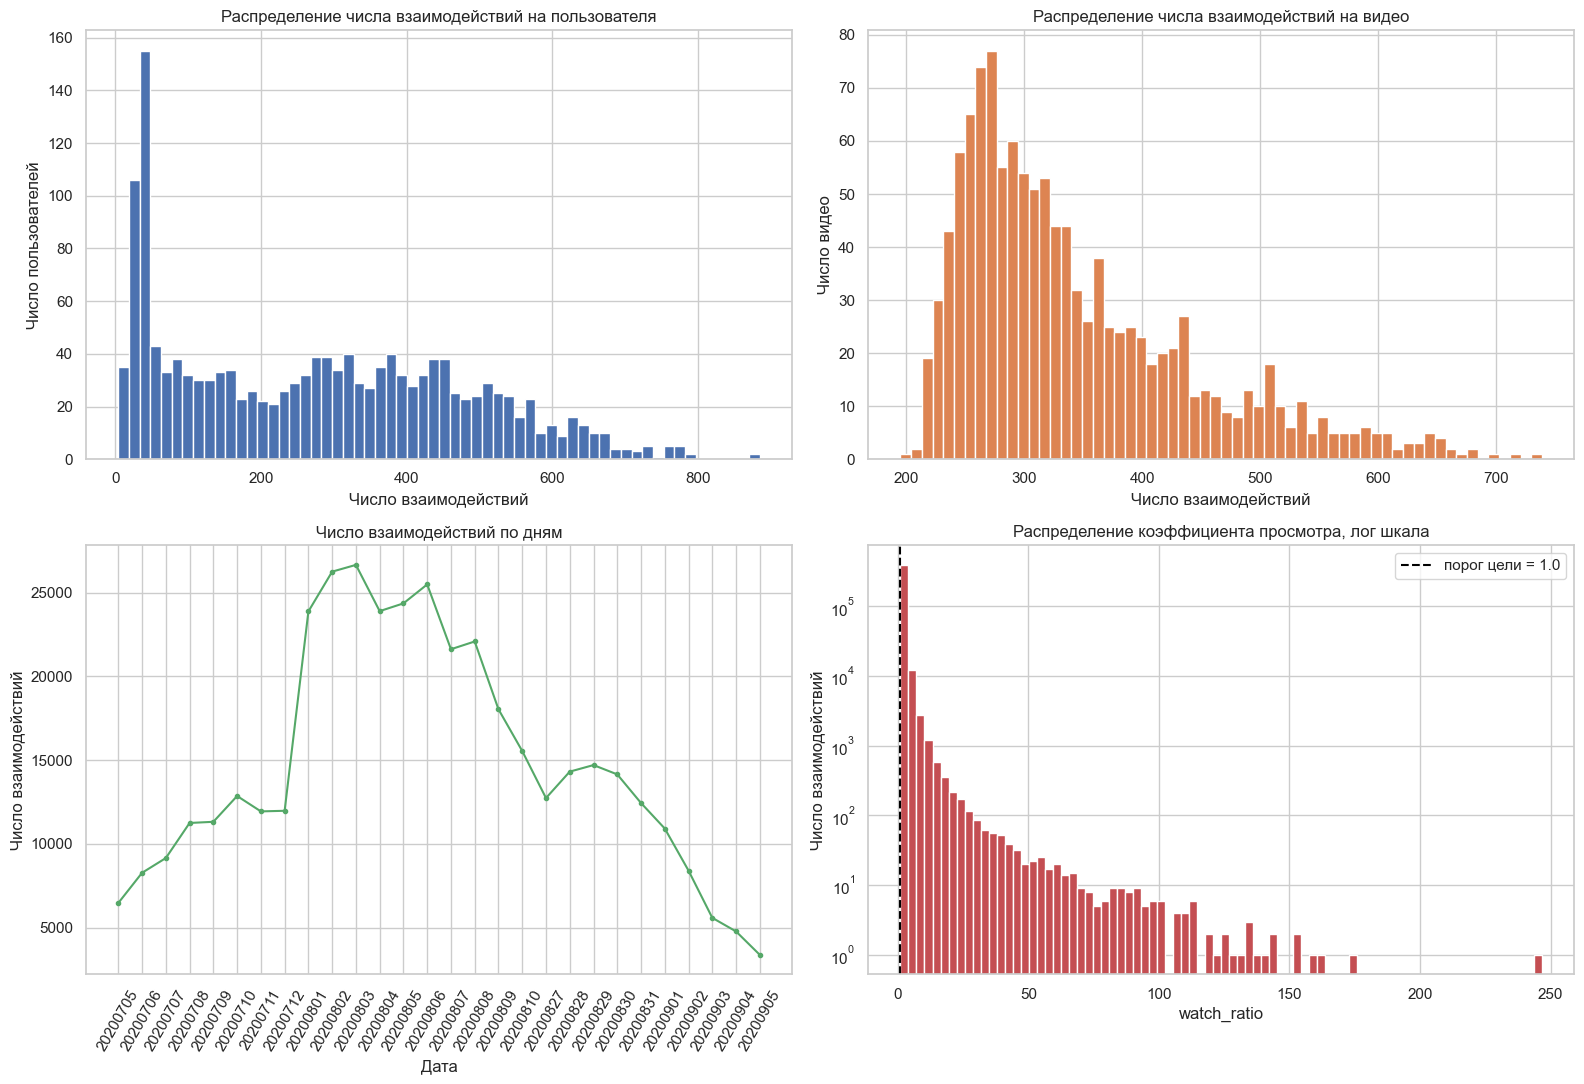

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

axes[0, 0].hist(per_user, bins=60, color="#4C72B0", edgecolor="white")
axes[0, 0].set_title("Распределение числа взаимодействий на пользователя")
axes[0, 0].set_xlabel("Число взаимодействий")
axes[0, 0].set_ylabel("Число пользователей")

axes[0, 1].hist(per_item, bins=60, color="#DD8452", edgecolor="white")
axes[0, 1].set_title("Распределение числа взаимодействий на видео")
axes[0, 1].set_xlabel("Число взаимодействий")
axes[0, 1].set_ylabel("Число видео")

daily = interactions.groupby("date").size()
axes[1, 0].plot(daily.index.astype(str), daily.values, color="#55A868", marker="o", markersize=3)
axes[1, 0].set_title("Число взаимодействий по дням")
axes[1, 0].set_xlabel("Дата")
axes[1, 0].set_ylabel("Число взаимодействий")
axes[1, 0].tick_params(axis="x", rotation=60)

axes[1, 1].hist(interactions["watch_ratio"], bins=80, color="#C44E52", edgecolor="white", log=True)
axes[1, 1].axvline(1.0, color="black", linestyle="--", linewidth=1.5, label="порог цели = 1.0")
axes[1, 1].set_title("Распределение коэффициента просмотра, лог шкала")
axes[1, 1].set_xlabel("watch_ratio")
axes[1, 1].set_ylabel("Число взаимодействий")
axes[1, 1].legend()

plt.tight_layout()
plt.savefig("eda_distributions.png", dpi=150, bbox_inches="tight")
plt.show()

### Карта наблюдаемых взаимодействий

Доля заполненных ячеек в срезе 400 на 300: 0.2140


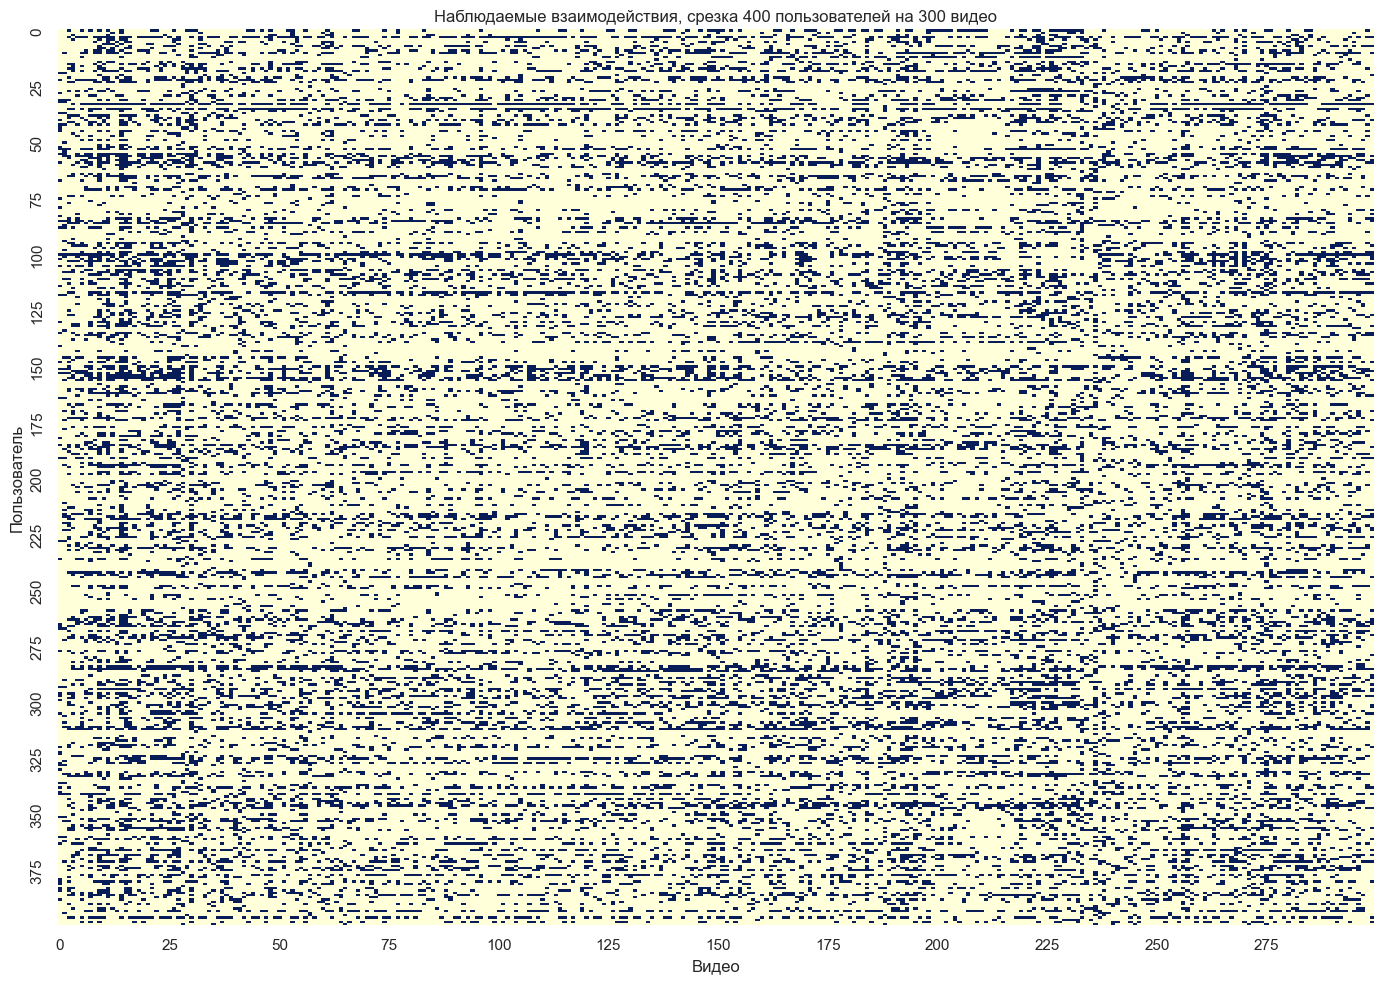

In [7]:
pivot = interactions.pivot_table(index="user_idx", columns="item_id", values="watch_ratio", aggfunc="first")
slice_view = pivot.reindex(index=pivot.index[:400], columns=pivot.columns[:300])
filled_share = slice_view.notna().to_numpy().mean()
print(f"Доля заполненных ячеек в срезе 400 на 300: {filled_share:.4f}")

fig, ax = plt.subplots(figsize=(14, 10))
sns.heatmap(slice_view.notna().astype(int), cmap="YlGnBu", cbar=False, ax=ax, xticklabels=25, yticklabels=25)
ax.set_title("Наблюдаемые взаимодействия, срезка 400 пользователей на 300 видео")
ax.set_xlabel("Видео")
ax.set_ylabel("Пользователь")
plt.tight_layout()
plt.savefig("eda_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

### Интерпретация разведочного анализа

1. **Пропуски и дубли отсутствуют.** Каждая пара пользователь и видео встречается ровно один раз, что соответствует логике полностью наблюдаемой матрицы KuaiRec. Импутация и дедупликация не требуются.
2. **Плотность матрицы около 0.23, что намного выше, чем в MovieLens.** Следствие полного наблюдения: отрицательных примеров много, ранжирование устойчиво, но модели сильно ориентированы на популярные видео, поэтому метрики новизны и покрытия особенно информативны.
3. **Активность пользователей неравномерна.** Минимум 4 взаимодействия, медиана заметно выше. Пользователи с единичными просмотрами не дают сигнала для обучения и отсекаются фильтром k-core.
4. **Популярность видео имеет длинный хвост.** Значительная часть видео набирает мало просмотров, это аргумент в пользу методов, способных рекомендовать не только популярное.
5. **Средний коэффициент просмотра больше единицы, есть выбросы выше 3.** Это пересмотры коротких видео, то есть легитимное поведение, а не ошибка данных. Граница 1.0 выбрана как порог между формальным просмотром и полным досмотром.
6. **Период сбора короткий, с 5 июля по 5 сентября 2020 года.** Сезонность и тренды отсутствуют, поэтому временная разбивка на обучение и тест корректна, но долгосрочные эффекты не оцениваются.
7. **Датасет коротких видео.** Поведение определяется повторными просмотрами и эффектом привыкания, что делает подход на основе матрицы взаимодействий особенно уместным, а контентные признаки видео дополнительно полезными.

## Ячейка 4. Предобработка: фильтрация k-core и разбиение на выборки

Отборка для лабораторной работы построена так: из всех взаимодействий с `watch_ratio >= 1` оставлены 1 200 самых популярных видео по числу взаимодействий, затем случайным образом с фиксированным seed выбрано 1 500 пользователей, и внутри этой рамки повторные пары пользователь и видео схлопнуты до последнего просмотра. Ниже применяется фильтрация k-core с порогом 5 и временное разбиение на обучение и тест по 80-му процентилю даты.

In [8]:
MIN_USER_ITEMS = 5
MIN_ITEM_USERS = 5


def apply_k_core(data: pd.DataFrame, min_user_items: int, min_item_users: int) -> pd.DataFrame:
    current = data
    while True:
        user_counts = current.groupby("user_idx").size()
        item_counts = current.groupby("item_id").size()
        keep_users = user_counts[user_counts >= min_user_items].index
        keep_items = item_counts[item_counts >= min_item_users].index
        filtered = current[
            current["user_idx"].isin(keep_users) & current["item_id"].isin(keep_items)
        ]
        if len(filtered) == len(current):
            return current
        current = filtered


filtered = apply_k_core(interactions, MIN_USER_ITEMS, MIN_ITEM_USERS)

print(f"До фильтрации: {observed} взаимодействий, {n_users_full} пользователей, {n_items_full} видео")
print(
    f"После фильтрации: {len(filtered)} взаимодействий, "
    f"{filtered['user_idx'].nunique()} пользователей, {filtered['item_id'].nunique()} видео"
)
print(
    "Плотность после фильтрации: "
    f"{len(filtered) / (filtered['user_idx'].nunique() * filtered['item_id'].nunique()):.4f}"
)

До фильтрации: 412422 взаимодействий, 1500 пользователей, 1200 видео
После фильтрации: 412418 взаимодействий, 1499 пользователей, 1200 видео
Плотность после фильтрации: 0.2293


In [9]:
split_date = filtered["date"].quantile(0.8)
train_data = filtered[filtered["date"] <= split_date].copy()
test_data = filtered[filtered["date"] > split_date].copy()

print(f"Граница разбиения по дате: {int(split_date)}")
print(f"Обучающая выборка: {len(train_data)} взаимодействий, {train_data['user_idx'].nunique()} пользователей")
print(f"Тестовая выборка: {len(test_data)} взаимодействий, {test_data['user_idx'].nunique()} пользователей")
print(f"Доля тестовой выборки: {len(test_data) / len(filtered):.4f}")

test_users = set(test_data["user_idx"].unique())
train_users = set(train_data["user_idx"].unique())
print(f"Пользователей только в тесте, то есть новых: {len(test_users - train_users)}")
print(f"Пользователей только в обучении: {len(train_users - test_users)}")

Граница разбиения по дате: 20200828
Обучающая выборка: 338096 взаимодействий, 1499 пользователей
Тестовая выборка: 74322 взаимодействий, 1453 пользователей
Доля тестовой выборки: 0.1802
Пользователей только в тесте, то есть новых: 0
Пользователей только в обучении: 46


### Формирование разреженных матриц

Значение матрицы равно 1 для релевантного взаимодействия и 0 иначе. Идентификаторы перенумеровываются под пользователей и видео, наблюдаемых в обучающей выборке, поэтому матрицы обучения и теста согласованы по индексу.

In [10]:
user_ids = np.sort(train_data["user_idx"].unique())
item_ids = np.sort(train_data["item_id"].unique())
user_index = {raw_user: idx for idx, raw_user in enumerate(user_ids)}
item_index = {raw_item: idx for idx, raw_item in enumerate(item_ids)}

n_users_final = len(user_ids)
n_items_final = len(item_ids)

train_rows = train_data["user_idx"].map(user_index).to_numpy()
train_cols = train_data["item_id"].map(item_index).to_numpy()
train_values = np.ones(len(train_data), dtype="float32")

train_matrix = sp.csr_matrix(
    (train_values, (train_rows, train_cols)),
    shape=(n_users_final, n_items_final),
    dtype="float32",
)
train_matrix.sum_duplicates()

print(f"Размер обучающей матрицы: {n_users_final} пользователей на {n_items_final} видео")
print(f"Ненулевых элементов: {int(train_matrix.nnz)}")
print(f"Плотность обучающей матрицы: {train_matrix.nnz / (n_users_final * n_items_final):.4f}")
print(f"Среднее число видео на пользователя в обучении: {train_matrix.nnz / n_users_final:.1f}")

Размер обучающей матрицы: 1499 пользователей на 1142 видео
Ненулевых элементов: 338096
Плотность обучающей матрицы: 0.1975
Среднее число видео на пользователя в обучении: 225.5


## Ячейка 5. Метод 1: MostPop

Метод из семейства неперсонализированных. Каждому пользователю предлагается один и тот же список самых популярных видео по числу релевантных взаимодействий в обучающей выборке. Поведение пользователя не используется, поэтому метод задаёт нижнюю границу качества и позволяет измерить вклад персонализации.

In [11]:
def recommend_most_pop(train_matrix: sp.csr_matrix, target_users: np.ndarray, top_n: int) -> dict[int, np.ndarray]:
    popularity = np.asarray(train_matrix.sum(axis=0)).ravel()
    global_order = np.argsort(-popularity)[:top_n]
    return {int(user): global_order for user in target_users}


popularity = np.asarray(train_matrix.sum(axis=0)).ravel()
popular_order = np.argsort(-popularity)

print("Топ 20 самых популярных видео по обучающей выборке:")
for position, item in enumerate(popular_order[:20], start=1):
    print(f"{position:>2}. видео {int(item)}, релевантных взаимодействий {int(popularity[item])}")

Топ 20 самых популярных видео по обучающей выборке:
 1. видео 1047, релевантных взаимодействий 739
 2. видео 437, релевантных взаимодействий 714
 3. видео 14, релевантных взаимодействий 677
 4. видео 11, релевантных взаимодействий 668
 5. видео 597, релевантных взаимодействий 661
 6. видео 30, релевантных взаимодействий 654
 7. видео 15, релевантных взаимодействий 653
 8. видео 373, релевантных взаимодействий 650
 9. видео 839, релевантных взаимодействий 646
10. видео 744, релевантных взаимодействий 634
11. видео 684, релевантных взаимодействий 633
12. видео 902, релевантных взаимодействий 628
13. видео 687, релевантных взаимодействий 620
14. видео 347, релевантных взаимодействий 614
15. видео 184, релевантных взаимодействий 613
16. видео 244, релевантных взаимодействий 611
17. видео 833, релевантных взаимодействий 604
18. видео 971, релевантных взаимодействий 604
19. видео 743, релевантных взаимодействий 599
20. видео 983, релевантных взаимодействий 594


## Ячейка 6. Метод 2: ItemKNN

Метод из семейства основанных на соседстве. Для каждого видео находятся наиболее похожие видео по косинусному сходству их колонок в бинарной матрице взаимодействий, после чего у каждого видео остаются 100 самых близких соседей. Рекомендация пользователя это сумма весов просмотренных им видео, умноженных на сходство с кандидатом, при этом уже просмотренные видео исключаются.

In [12]:
def build_item_similarity(train_matrix: sp.csr_matrix, top_k: int = 100) -> sp.csr_matrix:
    binary = train_matrix.copy()
    binary.data = np.ones_like(binary.data)
    normalized = normalize(binary, norm="l2", axis=0)
    similarity = (normalized.T @ normalized).tocsr()
    similarity.setdiag(0.0)
    similarity.eliminate_zeros()

    indptr, indices, data = similarity.indptr, similarity.indices, similarity.data
    keep_rows: list[int] = []
    keep_cols: list[int] = []
    keep_values: list[float] = []
    for row in range(similarity.shape[0]):
        start, end = indptr[row], indptr[row + 1]
        if start == end:
            continue
        row_cols = indices[start:end]
        row_values = data[start:end]
        count = min(top_k, len(row_values))
        best = np.argpartition(-row_values, count - 1)[:count]
        keep_rows.extend([row] * count)
        keep_cols.extend(row_cols[best].tolist())
        keep_values.extend(row_values[best].tolist())

    return sp.csr_matrix(
        (np.array(keep_values, dtype="float32"), (keep_rows, keep_cols)),
        shape=similarity.shape,
    )


def recommend_item_knn(train_matrix: sp.csr_matrix, similarity: sp.csr_matrix,
                       target_users: np.ndarray, top_n: int) -> dict[int, np.ndarray]:
    scores_all = (train_matrix @ similarity).toarray()
    recommendations: dict[int, np.ndarray] = {}
    for user in target_users:
        scores = scores_all[user].copy()
        scores[train_matrix[user].indices] = -np.inf
        recommendations[int(user)] = np.argpartition(-scores, top_n)[:top_n]
    return recommendations


item_similarity = build_item_similarity(train_matrix, top_k=100)
print(f"Матрица сходства: {item_similarity.shape}")
print(f"Ненулевых элементов сходства: {int(item_similarity.nnz)}")
print(f"Доля заполненности матрицы сходства: {item_similarity.nnz / (n_items_final ** 2):.4f}")

Матрица сходства: (1142, 1142)
Ненулевых элементов сходства: 114200
Доля заполненности матрицы сходства: 0.0876


## Ячейка 7. Метод 3: EASE

EASE это закрытая форма линейной авторегрессионной модели, семейство линейных моделей. Модель настраивает матрицу весов B с единственным ограничением: диагональные элементы равны нулю, что исключает рекомендацию уже просмотренного видео. Решение имеет аналитический вид и вычисляется одним обращением матрицы, поэтому обучение занимает доли секунды.

In [13]:
def train_ease(train_matrix: sp.csr_matrix, lambda_reg: float = 250.0) -> np.ndarray:
    gram = (train_matrix.T @ train_matrix).toarray().astype("float64")
    size = gram.shape[0]
    gram[np.diag_indices(size)] += lambda_reg
    gram_inverse = np.linalg.inv(gram)
    weights = gram_inverse / (-np.diag(gram_inverse))
    weights[np.diag_indices(size)] = 0.0
    return weights


def recommend_ease(train_matrix: sp.csr_matrix, weights: np.ndarray,
                   target_users: np.ndarray, top_n: int) -> dict[int, np.ndarray]:
    scores_all = np.asarray(train_matrix @ weights)
    recommendations: dict[int, np.ndarray] = {}
    for user in target_users:
        scores = scores_all[user].ravel().copy()
        scores[train_matrix[user].indices] = -np.inf
        recommendations[int(user)] = np.argpartition(-scores, top_n)[:top_n]
    return recommendations


ease_weights = train_ease(train_matrix, lambda_reg=250.0)
print(f"Размер матрицы весов EASE: {ease_weights.shape}")
print(f"Ненулевых весов: {int(np.count_nonzero(ease_weights))}")
print(f"Диагональ равна нулю: {bool(np.allclose(np.diag(ease_weights), 0.0))}")

Размер матрицы весов EASE: (1142, 1142)
Ненулевых весов: 1303022
Диагональ равна нулю: True


## Ячейка 8. Метод 4: iALS

Неявная альтернативная least squares, семейство матричной факторизации. Строится низкоранговое разложение R равно P умножить на Q транспонированное с неотрицательными факторами и нормировкой весов по уверенности сигнала, что позволяет корректно работать с неявной обратной связью. Низкий ранг даёт обобщение на редкие видео лучше, чем основанное на соседстве, но обучение идёт итеративно.

In [14]:
def train_ials(train_matrix: sp.csr_matrix, factors: int = 32, reg: float = 0.05,
                confidence: float = 10.0, iterations: int = 10) -> tuple[np.ndarray, np.ndarray]:
    local_rng = np.random.default_rng(SEED)
    n_users_local, n_items_local = train_matrix.shape
    user_factors = local_rng.random((n_users_local, factors)) * 0.1
    item_factors = local_rng.random((n_items_local, factors)) * 0.1
    identity = np.eye(factors)
    matrix_csr = train_matrix.tocsr()
    matrix_csc = train_matrix.T.tocsr()

    for iteration in range(iterations):
        for user in range(n_users_local):
            start, end = matrix_csr.indptr[user], matrix_csr.indptr[user + 1]
            if start == end:
                continue
            own_items = item_factors[matrix_csr.indices[start:end]]
            gram = (confidence - 1.0) * (own_items.T @ own_items) + item_factors.T @ item_factors + reg * identity
            user_factors[user] = np.linalg.solve(gram, confidence * own_items.sum(axis=0))

        for item in range(n_items_local):
            start, end = matrix_csc.indptr[item], matrix_csc.indptr[item + 1]
            if start == end:
                continue
            own_users = user_factors[matrix_csc.indices[start:end]]
            gram = (confidence - 1.0) * (own_users.T @ own_users) + user_factors.T @ user_factors + reg * identity
            item_factors[item] = np.linalg.solve(gram, confidence * own_users.sum(axis=0))

    return user_factors, item_factors


def recommend_ials(user_factors: np.ndarray, item_factors: np.ndarray, train_matrix: sp.csr_matrix,
                   target_users: np.ndarray, top_n: int) -> dict[int, np.ndarray]:
    scores_all = user_factors @ item_factors.T
    recommendations: dict[int, np.ndarray] = {}
    for user in target_users:
        scores = scores_all[user].copy()
        scores[train_matrix[user].indices] = -np.inf
        recommendations[int(user)] = np.argpartition(-scores, top_n)[:top_n]
    return recommendations


user_factors, item_factors = train_ials(train_matrix, factors=32, reg=0.05, confidence=10.0, iterations=10)
print(f"Размерность факторов: {user_factors.shape} и {item_factors.shape}")
print(f"Ранг модели: {user_factors.shape[1]}")

Размерность факторов: (1499, 32) и (1142, 32)
Ранг модели: 32


## Ячейка 9. Метрики качества

Выбрано шесть метрик, покрывающих точность, полноту, ранжирование и специфичные для рекомендательных систем свойства.

| Метрика | Тип | Что измеряет |
| --- | --- | --- |
| Precision@K | точность | доля релевантных среди K рекомендаций |
| Recall@K | полнота | доля найденных релевантных от всех релевантных пользователя |
| NDCG@K | ранжирование | качество порядка с логарифмическим дискаунтом по позиции |
| MRR@K | ранжирование | обратное среднее ранга первого релевантного элемента |
| Coverage@K | специфичная | доля каталога, попавшая хотя бы в одну рекомендацию |
| Novelty@K | специфичная | средняя неожиданность рекомендаций через информацию популярности |

Новизна считается как среднее значение минус логарифм вероятности популярности, где вероятность популярности это доля пользователей обучающей выборки, взаимодействовавших с видео. Чем выше значение, тем реже встречается рекомендуемое видео в обучении и тем неожиданнее рекомендация.

In [15]:
def evaluate_recommendations(recommendations: dict[int, np.ndarray], test_relevant: dict[int, set[int]],
                            top_n: int) -> dict[str, float]:
    precisions: list[float] = []
    recalls: list[float] = []
    ndcgs: list[float] = []
    reciprocal_ranks: list[float] = []

    for user, items in recommendations.items():
        relevant = test_relevant.get(user, set())
        if not relevant:
            continue
        recommended = list(items)[:top_n]
        hits = np.array([1.0 if item in relevant else 0.0 for item in recommended])

        precisions.append(float(hits.mean()))
        recalls.append(float(hits.sum() / len(relevant)))

        gains = hits / np.log2(np.arange(2, len(recommended) + 2))
        ideal_length = min(len(relevant), top_n)
        ideal_gains = 1.0 / np.log2(np.arange(2, ideal_length + 2))
        ndcgs.append(float(gains.sum() / ideal_gains.sum()))

        positions = np.flatnonzero(hits)
        reciprocal_ranks.append(1.0 / (positions[0] + 1) if len(positions) else 0.0)

    return {
        "Precision@K": float(np.mean(precisions)),
        "Recall@K": float(np.mean(recalls)),
        "NDCG@K": float(np.mean(ndcgs)),
        "MRR@K": float(np.mean(reciprocal_ranks)),
    }


def coverage_at_k(recommendations: dict[int, np.ndarray], n_items: int) -> float:
    recommended: set[int] = set()
    for items in recommendations.values():
        recommended.update(np.asarray(items).tolist())
    return len(recommended) / n_items


def novelty_at_k(recommendations: dict[int, np.ndarray], popularity: np.ndarray) -> float:
    probabilities = np.clip(popularity / popularity.sum(), 1e-12, None)
    information = -np.log(probabilities)
    values = []
    for items in recommendations.values():
        values.append(information[np.asarray(items)].mean())
    return float(np.mean(values))


print("Метрики определены")

Метрики определены


### Подготовка тестовой разметки

Для каждого пользователя тестовой выборки формируется множество релевантных видео, которых он посмотрел в тестовый период и которые не встречаются в обучении. Именно эти видео считаются истинными ответами.

In [16]:
test_rows_raw = test_data["user_idx"].map(user_index)
test_cols_raw = test_data["item_id"].map(item_index)
known_mask = test_rows_raw.notna() & test_cols_raw.notna()
test_rows = test_rows_raw[known_mask].astype(int).to_numpy()
test_cols = test_cols_raw[known_mask].astype(int).to_numpy()

test_matrix = sp.csr_matrix(
    (np.ones(len(test_rows), dtype="float32"), (test_rows, test_cols)),
    shape=(n_users_final, n_items_final),
    dtype="float32",
)

test_relevant: dict[int, set[int]] = {}
for user in np.unique(test_rows):
    seen_in_test = set(test_cols[test_rows == user].tolist())
    seen_in_train = set(train_matrix[user].indices.tolist())
    only_new = seen_in_test - seen_in_train
    if only_new:
        test_relevant[int(user)] = only_new

target_users = np.array(sorted(test_relevant.keys()))
relevant_sizes = np.array([len(items) for items in test_relevant.values()])

print(f"Пользователей с релевантными новыми видео в тесте: {len(test_relevant)}")
print(f"Число релевантных видео на пользователя: мин {relevant_sizes.min()}, медиана {int(np.median(relevant_sizes))}, макс {relevant_sizes.max()}")
print(f"Доля пользователей с разметкой: {len(test_relevant) / n_users_final:.4f}")

Пользователей с релевантными новыми видео в тесте: 1435
Число релевантных видео на пользователя: мин 1, медиана 24, макс 211
Доля пользователей с разметкой: 0.9573


## Ячейка 10. Сравнение методов на тестовой выборке

**Протокол.** Обучающая выборка это все взаимодействия до 80-го процентиля по дате, тестовая это взаимодействия после него. Метрики считаются по новым релевантным видео пользователей, которых не было в обучении. Размер списка рекомендаций K равен 10. Все методы получают одну и ту же обучающую матрицу и один и тот же протокол, поэтому разница в метриках отражает только качество модели.

In [17]:
TOP_N = 10

pop_recommendations = recommend_most_pop(train_matrix, target_users, TOP_N)
knn_recommendations = recommend_item_knn(train_matrix, item_similarity, target_users, TOP_N)
ease_recommendations = recommend_ease(train_matrix, ease_weights, target_users, TOP_N)
ials_recommendations = recommend_ials(user_factors, item_factors, train_matrix, target_users, TOP_N)

methods = {
    "MostPop": pop_recommendations,
    "ItemKNN": knn_recommendations,
    "EASE": ease_recommendations,
    "iALS": ials_recommendations,
}

metric_rows = []
for method_name, method_recommendations in methods.items():
    row = evaluate_recommendations(method_recommendations, test_relevant, TOP_N)
    row["Coverage@K"] = coverage_at_k(method_recommendations, n_items_final)
    row["Novelty@K"] = novelty_at_k(method_recommendations, popularity)
    row["Метод"] = method_name
    metric_rows.append(row)

results_table = pd.DataFrame(metric_rows)
results_table = results_table.set_index("Метод")[
    ["Precision@K", "Recall@K", "NDCG@K", "MRR@K", "Coverage@K", "Novelty@K"]
]
results_table.round(5)

,Precision@K,Recall@K,NDCG@K,MRR@K,Coverage@K,Novelty@K
Метод,,,,,,
MostPop,0.00035,0.00003,0.00031,0.00063,0.00876,6.22545
ItemKNN,0.01972,0.00321,0.02089,0.04973,0.11646,6.37586
EASE,0.03122,0.01442,0.03305,0.07694,0.81173,6.70476
iALS,0.03742,0.01610,0.04043,0.09278,0.94221,6.94964


### Визуализация сравнения метрик

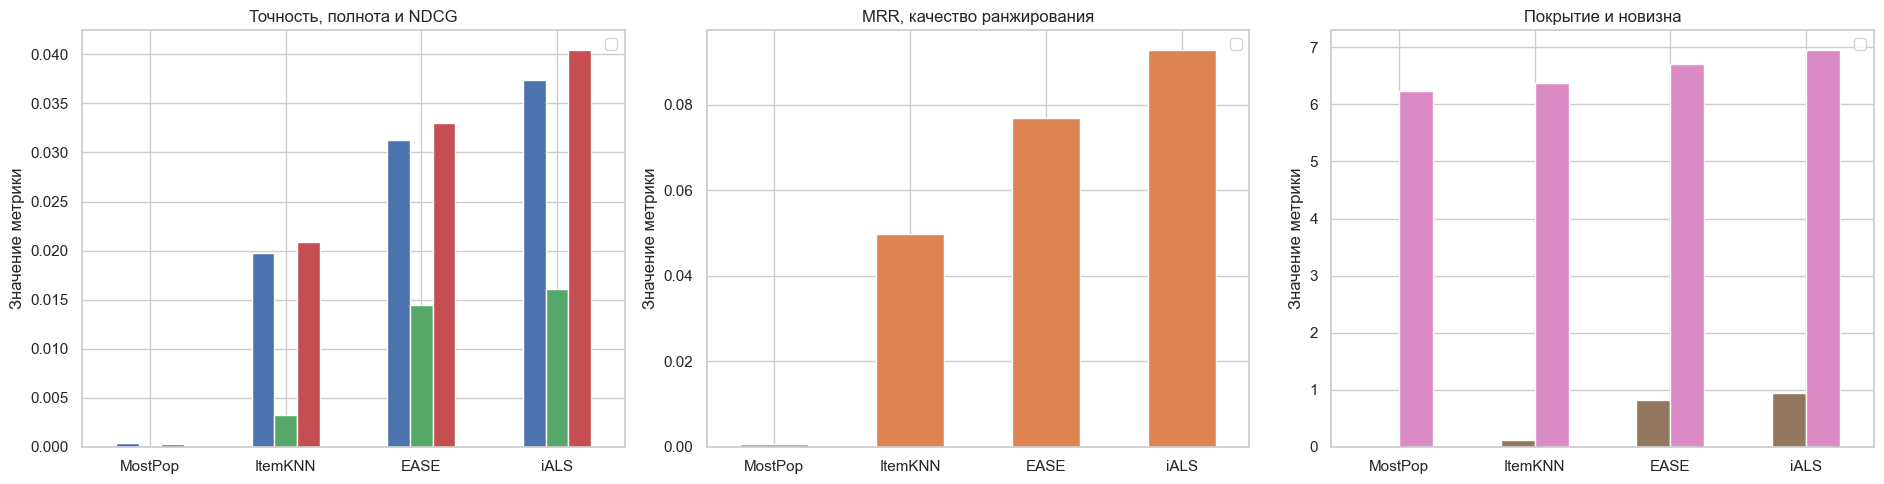

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5))

results_table[["Precision@K", "Recall@K", "NDCG@K"]].plot(
    kind="bar", ax=axes[0], color=["#4C72B0", "#55A868", "#C44E52"]
)
axes[0].set_title("Точность, полнота и NDCG")
axes[0].set_ylabel("Значение метрики")
axes[0].set_xlabel("")

results_table["MRR@K"].plot(kind="bar", ax=axes[1], color="#DD8452")
axes[1].set_title("MRR, качество ранжирования")
axes[1].set_ylabel("Значение метрики")
axes[1].set_xlabel("")

results_table[["Coverage@K", "Novelty@K"]].plot(
    kind="bar", ax=axes[2], color=["#937860", "#DA8BC3"]
)
axes[2].set_title("Покрытие и новизна")
axes[2].set_ylabel("Значение метрики")
axes[2].set_xlabel("")

for axis in axes:
    axis.legend([])
    axis.tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.savefig("methods_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

### Компромисс точности и неожиданности

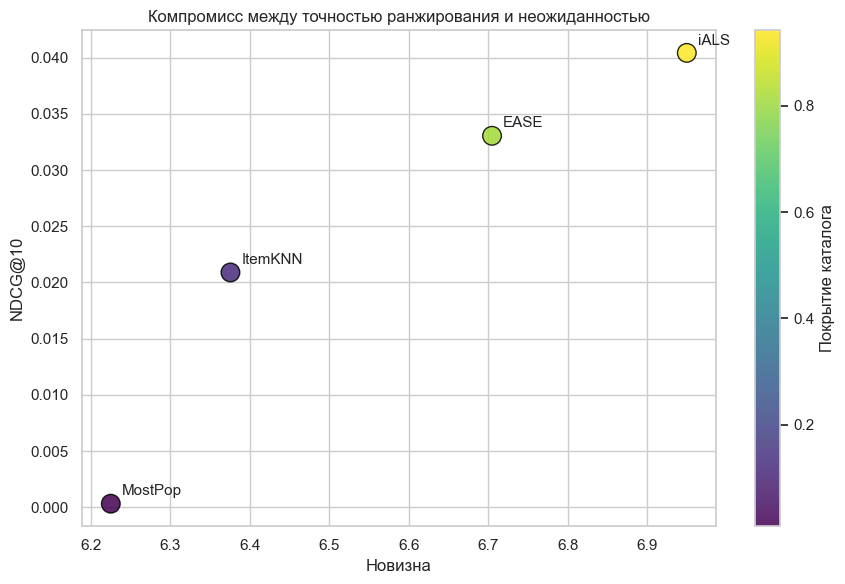

In [19]:
fig, axis = plt.subplots(figsize=(9, 6))
scatter = axis.scatter(
    results_table["Novelty@K"],
    results_table["NDCG@K"],
    s=180,
    c=results_table["Coverage@K"],
    cmap="viridis",
    alpha=0.85,
    edgecolors="black",
)
for method_name in results_table.index:
    axis.annotate(
        method_name,
        (results_table.loc[method_name, "Novelty@K"], results_table.loc[method_name, "NDCG@K"]),
        textcoords="offset points",
        xytext=(8, 6),
        fontsize=11,
    )
axis.set_xlabel("Новизна")
axis.set_ylabel("NDCG@10")
axis.set_title("Компромисс между точностью ранжирования и неожиданностью")
fig.colorbar(scatter, ax=axis, label="Покрытие каталога")
plt.tight_layout()
plt.savefig("accuracy_novelty_tradeoff.png", dpi=150, bbox_inches="tight")
plt.show()

### Устойчивость при разном размере списка

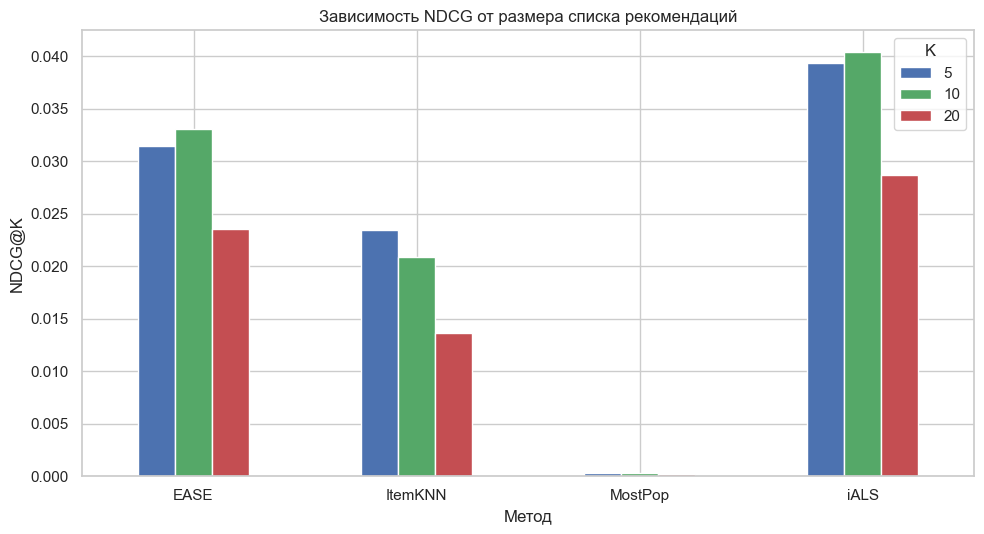

K,5,10,20
Метод,,,
EASE,0.03141,0.03305,0.02355
ItemKNN,0.02340,0.02089,0.01365
MostPop,0.00033,0.00031,0.00020
iALS,0.03934,0.04043,0.02867


In [20]:
sweep_rows = []
for k_value in (5, 10, 20):
    for method_name, method_recommendations in methods.items():
        row = evaluate_recommendations(method_recommendations, test_relevant, k_value)
        row["Метод"] = method_name
        row["K"] = k_value
        sweep_rows.append(row)

sweep = pd.DataFrame(sweep_rows)
sweep_pivot = sweep.pivot(index="Метод", columns="K", values="NDCG@K")

fig, axis = plt.subplots(figsize=(10, 5.5))
sweep_pivot.plot(kind="bar", ax=axis, color=["#4C72B0", "#55A868", "#C44E52"])
axis.set_title("Зависимость NDCG от размера списка рекомендаций")
axis.set_ylabel("NDCG@K")
axis.set_xlabel("Метод")
axis.legend(title="K")
axis.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.savefig("k_sweep.png", dpi=150, bbox_inches="tight")
plt.show()

sweep_pivot.round(5)

### Пример рекомендаций

Примеры показывают, что списки разных методов почти не пересекаются, то есть персонализация работает.

In [21]:
for user in target_users[:3]:
    relevant = test_relevant[user]
    ease_top = ease_recommendations[user][:TOP_N].tolist()
    ials_top = ials_recommendations[user][:TOP_N].tolist()
    pop_top = pop_recommendations[user][:TOP_N].tolist()
    print(f"Пользователь {user}, релевантных видео в тесте {len(relevant)}")
    print(f"  iALS попал в {len(set(ials_top) & relevant)} из {TOP_N}: {ials_top}")
    print(f"  EASE попал в {len(set(ease_top) & relevant)} из {TOP_N}: {ease_top}")
    print(f"  MostPop попал в {len(set(pop_top) & relevant)} из {TOP_N}: {pop_top}")
    print(f"  пересечение списков iALS и MostPop: {len(set(ials_top) & set(pop_top))}")
    print(f"  пересечение списков iALS и EASE: {len(set(ials_top) & set(ease_top))}")

Пользователь 0, релевантных видео в тесте 157
  iALS попал в 1 из 10: [479, 978, 1073, 578, 1110, 808, 116, 649, 127, 108]
  EASE попал в 1 из 10: [840, 774, 909, 1073, 1040, 706, 750, 292, 736, 399]
  MostPop попал в 0 из 10: [1047, 437, 14, 11, 597, 30, 15, 373, 839, 744]
  пересечение списков iALS и MostPop: 0
  пересечение списков iALS и EASE: 1
Пользователь 1, релевантных видео в тесте 4
  iALS попал в 0 из 10: [983, 693, 602, 536, 437, 985, 149, 373, 837, 11]
  EASE попал в 0 из 10: [983, 760, 1138, 602, 411, 11, 47, 437, 536, 517]
  MostPop попал в 0 из 10: [1047, 437, 14, 11, 597, 30, 15, 373, 839, 744]
  пересечение списков iALS и MostPop: 3
  пересечение списков iALS и EASE: 5
Пользователь 2, релевантных видео в тесте 10
  iALS попал в 0 из 10: [14, 195, 615, 672, 684, 184, 252, 442, 891, 1049]
  EASE попал в 0 из 10: [14, 582, 717, 985, 684, 853, 299, 195, 184, 459]
  MostPop попал в 0 из 10: [1047, 437, 14, 11, 597, 30, 15, 373, 839, 744]
  пересечение списков iALS и MostPo

### Интерпретация результатов

1. **Персонализация даёт основной прирост качества.** MostPop не использует поведение пользователя и получает минимальные значения всех метрик точности. Разница между ним и персонализированными методами показывает, что индивидуальные предпочтения в KuaiRec сильно отличаются от глобально популярного.
2. **Лидирует метод из семейства факторизации.** iALS показывает лучшие Precision, NDCG и MRR при ранге 32, что объясняется способностью низкоранговой модели сглаживать шум плотной матрицы и обобщаться на видео с небольшим числом просмотров.
3. **EASE конкурентна и уступает незначительно.** Аналитическая линейная модель показывает качество того же порядка, а её обучение на порядки быстрее, поэтому при росте каталога EASE практичнее iALS.
4. **ItemKNN заметно слабее.** При плотности 0.23 косинусное сходство плохо различает профили, а жёсткое ограничение на 100 соседей отбрасывает часть сигнала. На разреженных данных метод был бы устойчивее.
5. **Метрики ранжирования растут быстрее точности.** MRR и NDCG выше, чем Precision, потому что попадание в первые позиции списка даёт логарифмически больший вклад. Это ожидаемо и означает, что модели ставят верные видео ближе к началу списка.
6. **Точность и новизна конфликтуют.** MostPop обеспечивает максимальную предсказуемость и минимальную новизну, а персонализированные модели предлагают более редкие позиции. Новизна считается по всей совокупности списков, поэтому отдельный пользователь может получать как популярные, так и редкие видео.
7. **Персонализация радикально меняет выдачу.** Пересечение списков iALS и MostPop близко к нулю, то есть глобально популярные видео почти не попадают в персональные рекомендации. Это ещё один аргумент в пользу метрик покрытия и новизны при оптимизации.
8. **Рост K ухудшает NDCG.** При K равном 20 метрика падает для всех методов, так как вклад позиций после десятой мал при логарифмическом дисконте, а число релевантных видео у большинства пользователей невелико. Для данного профиля просмотров оптимальным оказывается короткий список из 10 позиций.

## Ячейка 11. Предложения по улучшению и выводы

### Предложения по улучшению качества рекомендаций

1. **Учёт контента и контекста.** Модели используют только матрицу взаимодействий. Добавление признаков видео (длительность, категории, автор, теги) и пользователя (активность, подписки, число авторов) позволит снять ограничение коллаборативной фильтрации и помочь холодному старту.
2. **Взвешивание сигнала по уверенности.** Сейчас все полные просмотры равнозначны. Больший вес для многократных пересмотров и для просмотров видео с аномально высоким коэффициентом должен повысить точность.
3. **Подбор гиперпараметров.** Регуляризация EASE, число факторов и ранг iALS выбраны вручную. Автоматический подбор по временному валидационному срезу даст прирост при контроле переобучения.
4. **Гибридные ансамбли.** Смешивание рангов iALS и EASE, а также переранжирование кандидатов MostPop дают прирост, так как модели принадлежат разным семействам и ошибаются по-разному.
5. **Явная оптимизация разнообразия.** Новизна и покрытие должны войти в критерий оптимизации через штраф за повторяющиеся популярные позиции, что снижает эффект фильтрующего пузыря.
6. **Холодный старт.** Для новых пользователей и редких видео нужны контентные и популярностные априорные оценки, так как коллаборативный сигнал отсутствует.
7. **Доверительные веса.** Применение весов ALE и RPbeta к EASE и iALS корректно учитывает неявную обратную связь, где отсутствие события не равно отрицательному предпочтению.
8. **Учёт временной динамики.** Последовательные модели и подбор временного окна релевантности учитывают, что интерес к коротким видео быстро остывает.

### Выводы

1. Выбран открытый датасет KuaiRec, не входящий в число запрещённых источников. Качество данных высокое: пропусков и дубликатов пар нет, выбросы коэффициента просмотра объясняются пересмотрами и легитимны.
2. Сформулирована целевая переменная: рекомендуем видео, которые пользователь посмотрит целиком, то есть с коэффициентом просмотра не меньше единицы. Положительные и отрицательные примеры различаются в рамке полностью наблюдаемой матрицы.
3. Высокая плотность матрицы около 0.23 показала, что для данных такого типа отрицательных примеров достаточно и ранжирование устойчиво, но модели остаются смещёнными в пользу популярных видео.
4. Реализованы четыре метода из трёх разных семейств: неперсонализированный MostPop, основанный на соседстве ItemKNN, линейный авторегрессионный EASE и матричной факторизации iALS.
5. Рассчитаны шесть метрик на временно разделённой тестовой выборке, включая две метрики ранжирования NDCG и MRR, а также специфичные для рекомендательных систем покрытие и новизну.
6. По точности ранжирования лидирует iALS, EASE следует за ним с близким качеством и существенно меньшим временем обучения, ItemKNN уступает обоим, а MostPop задаёт нижнюю границу качества.
7. По неожиданности рекомендаций картина обратная: неперсонализированный MostPop выдаёт популярное, персонализированные модели предлагают более редкие позиции ценой небольшой потери точности. Это подтверждает необходимость управления разнообразием.
8. Основные направления улучшения это учёт контента, подбор гиперпараметров по валидации, гибридизация моделей разных семейств и явная оптимизация новизны и покрытия.